# V3: internal-layout similarity

We want useful architectural precedents based on **room programme and spatial arrangement**. V2 learns to redraw 128 px images; its 86% shifted-copy result measures recognition of the same drawing, not relevance between different homes.

This notebook builds an interpretable structural baseline before we train a new encoder. It includes annotation inspection, room/wall/door masks, rotation-aware search and a human-review benchmark. Section 8 adds the model: **v3, an autoencoder that turns a drawing into rooms**, so the search also works on uploaded plans.

Run the synthetic checks without data. The drawings come from the 128 px file of `01_autoencoder` (`data/cubicasa5k_128.npz`). The annotations are the 5,000 `model.svg` files of CubiCasa5K in `01_autoencoder/data/cubicasa5k/`: only those (44 MB) are needed, not the whole 5.5 GB zip. Install the project requirements in your notebook environment. Generated artifacts go under the ignored data directory; the original notebook and server remain unchanged.


In [1]:
from pathlib import Path
from collections import Counter
import json, re, hashlib, tempfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from matplotlib.colors import ListedColormap
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / '01_autoencoder' / 'notebook').is_dir()), None)
if PROJECT is None:
    raise RuntimeError('Open Jupyter from inside this project.')
DATASET_ROOT = Path(
    PROJECT / '01_autoencoder/data/cubicasa5k'
)
OUTPUT = PROJECT / '01_autoencoder/data/internal_layout_v3'
OUTPUT.mkdir(parents=True, exist_ok=True)
SIZE, SEED = 256, 42
RUN_COLLECTION = True  # Enable after inspecting annotation overlays.
MAX_PLANS = None       # e.g. 100 for debugging; None for the full collection.
TYPES = ('Bedroom','Bath','Sauna','Kitchen','LivingRoom','Dining','Circulation','Storage','Garage','Other')
TYPE_ID = {name:i+1 for i,name in enumerate(TYPES)}
ALIASES = {'HallWay':'Circulation','Hall':'Circulation','Entry':'Circulation',
           'DraughtLobby':'Circulation','Closet':'Storage','DressingRoom':'Storage',
           'Pantry':'Storage','CarPort':'Garage','Lounge':'LivingRoom','EatingArea':'Dining'}
COLOURS = ['white','#4477aa','#66ccee','#228833','#ccbb44','#ee6677',
           '#aa3377','#bbbbbb','#ddaa33','#009988','#9999cc']
WEIGHTS = {'counts':.30,'areas':.20,'positions':.40,'shape':.10}
FLOORS = {'counts':1.,'areas':.02,'positions':.01,'shape':.10}
print('Dataset:', DATASET_ROOT, '| exists:', DATASET_ROOT.exists())


Dataset: /Users/luca_obejdeanu/Downloads/hackathon-team6-floorplan-similarity/01_autoencoder/data/cubicasa5k | exists: True


In [2]:
#the drawings we already have: the 5,000 plans at 128 px from 01_autoencoder (walls bright, 0-255)
#we only downloaded the model.svg files from the zip; the drawings come from here
data = np.load(PROJECT / '01_autoencoder/data/cubicasa5k_128.npz')
plan_ids, plan_splits = data['ids'], data['splits']
row_of = {pid: i for i, pid in enumerate(plan_ids)}


def drawing(pid):
    #a plan as drawn: dark lines on white, 128 x 128
    return 255 - data['images'][row_of[pid]]

## 1. Define a useful match

Initial ranking weights are **30% room counts, 20% area proportions, 40% spatial arrangement, 10% footprint proportions**. These are hypotheses: tune on validation queries, then freeze before reviewing test queries.

Bathroom and sauna stay separate. Counts describe annotation instances, which may differ from an architect's room programme for open-plan homes. Unknown room types become `Other`; original labels remain available for audit. Outdoor rooms are excluded. Areas are relative, not square metres.

Search tests four right-angle rotations of each complete plan. Reflections are not included. **Door connectivity is not scored yet:** nearby rooms do not necessarily connect, and a door mask alone does not establish the room pair. We must visually validate that extraction before relying on it.


## 2. Read SVG annotations and preserve geometry

The [official CubiCasa loader](https://github.com/CubiCasa/CubiCasa5k/blob/master/floortrans/loaders/house.py) identifies `Space` groups and `Wall`, `Door`, `Window` IDs. Its [dataset loader](https://github.com/CubiCasa/CubiCasa5k/blob/master/floortrans/loaders/svg_loader.py) pairs `model.svg` with `F1_scaled.png`.

This restricted reader takes the first polygon of each semantic group and supports inherited SVG affine transforms. Unsupported geometry fails visibly rather than generating an empty plan. It is not a general SVG renderer. Verify the coordinate alignment on real drawings before building features.

We crop using internal rooms plus structure, preserve aspect ratio, and draw categorical polygons directly at 256 px. The saved transform maps original coordinates into the square. Footprint here means room regions plus walls, not a reconstructed exterior boundary.


In [3]:
NUMBER = r'[-+]?(?:\d*\.\d+|\d+\.?\d*)(?:[eE][-+]?\d+)?'
def transform(text):
    matrix = np.eye(3)
    if re.sub(r'[A-Za-z]+\s*\([^)]*\)', '', text).strip(' ,\t\n'):
        raise ValueError(f'Unsupported transform: {text}')
    for name,args in re.findall(r'([A-Za-z]+)\s*\(([^)]*)\)',text):
        a = [float(v) for v in re.findall(NUMBER,args)]; t = np.eye(3)
        if name == 'matrix' and len(a)==6:
            t = np.array([[a[0],a[2],a[4]],[a[1],a[3],a[5]],[0,0,1.]])
        elif name == 'translate' and len(a) in (1,2):
            t[:2,2] = [a[0],a[1] if len(a)==2 else 0]
        elif name == 'scale' and len(a) in (1,2):
            t[0,0],t[1,1] = a[0],a[-1]
        elif name == 'rotate' and len(a) in (1,3):
            c,s = np.cos(np.deg2rad(a[0])),np.sin(np.deg2rad(a[0]))
            t[:2,:2] = [[c,-s],[s,c]]
            if len(a)==3:
                center=np.array(a[1:]); t[:2,2]=center-t[:2,:2]@center
        elif name in ('skewX','skewY') and len(a)==1:
            t[0 if name=='skewX' else 1,1 if name=='skewX' else 0]=np.tan(np.deg2rad(a[0]))
        else:
            raise ValueError(f'Unsupported transform: {name}({args})')
        matrix = matrix @ t
    return matrix

def read_svg(path):
    root=ET.parse(path).getroot(); found={}; expected={}
    def walk(element,parent,semantic=None,token=None):
        matrix=parent@transform(element.get('transform',''))
        classes=element.get('class','').split(); ident=element.get('id','')
        if 'Space' in classes:
            position=classes.index('Space')
            if position+1>=len(classes): raise ValueError('Space without a type')
            semantic=('room',classes[position+1]); token=id(element); expected[token]=semantic
        elif ident in ('Wall','Door','Window'):
            semantic=(ident.lower(),ident); token=id(element); expected[token]=semantic
        if element.tag.split('}')[-1]=='polygon' and semantic and token not in found:
            values=[float(v) for v in re.findall(NUMBER,element.get('points',''))]
            if len(values)<6 or len(values)%2: raise ValueError('Invalid polygon')
            xy=np.array(values).reshape(-1,2)
            xy=(np.column_stack([xy,np.ones(len(xy))])@matrix.T)[:,:2]
            if not np.isfinite(xy).all(): raise ValueError('Non-finite coordinates')
            raw=semantic[1]
            found[token]={'kind':semantic[0],'raw_type':raw,'points':xy,
                          'type':ALIASES.get(raw,raw if raw in TYPE_ID else 'Other')}
        for child in element: walk(child,matrix,semantic,token)
    walk(root,np.eye(3))
    if set(expected)-set(found): raise ValueError('Semantic group without supported polygon')
    records=list(found.values())
    if not any(r['kind']=='room' and r['raw_type']!='Outdoor' for r in records):
        raise ValueError('No internal room polygons')
    return records

def rasterize(records):
    rooms=[r for r in records if r['kind']=='room' and r['raw_type']!='Outdoor']
    structure=[r for r in records if r['kind'] in ('wall','door','window')]
    xy=np.concatenate([r['points'] for r in rooms+structure])
    lo,hi=xy.min(axis=0),xy.max(axis=0); side=float((hi-lo).max())
    if side<=0: raise ValueError('Degenerate bounds')
    scale=(SIZE-5)/side; offset=(SIZE-(hi-lo)*scale)/2-lo*scale
    def polygon(r): return [tuple(p) for p in r['points']*scale+offset]
    instance=Image.new('I',(SIZE,SIZE),0); semantic=Image.new('L',(SIZE,SIZE),0)
    for i,room in enumerate(rooms,1):
        ImageDraw.Draw(instance).polygon(polygon(room),fill=i)
        ImageDraw.Draw(semantic).polygon(polygon(room),fill=TYPE_ID[room['type']])
    masks={'instance':np.asarray(instance,dtype=np.int32),'semantic':np.asarray(semantic,dtype=np.uint8)}
    for kind in ('wall','door','window'):
        image=Image.new('L',(SIZE,SIZE),0)
        for r in structure:
            if r['kind']==kind: ImageDraw.Draw(image).polygon(polygon(r),fill=1)
        masks[kind]=np.asarray(image,dtype=np.uint8)
    if any(not (masks['instance']==i).any() for i in range(1,len(rooms)+1)):
        raise ValueError('A room vanished or was overwritten at this resolution')
    masks['footprint']=((masks['instance']>0)|(masks['wall']>0)).astype(np.uint8)
    return {'rooms':rooms,'masks':masks,'transform':{'scale':scale,'offset':offset.tolist(),
            'bounds':[lo.tolist(),hi.tolist()],'size':SIZE}}

def load_plan(folder):
    layout=rasterize(read_svg(Path(folder)/'model.svg')); layout['folder']=str(folder)
    return layout


## 3. Inspect drawings and masks

Look for room boundaries displaced from the original drawing, missing spaces, tiny rooms, unexpected `Other` labels and lost doors. Stop and fix alignment problems before trusting search. Thin details can still disappear at 256 px.

The drawing below is the 128 px version from `01_autoencoder`; the categorical map is cropped to the plan and padded. The colour legend distinguishes categories, not room instances. Red/green/blue in the last panel indicate walls/doors/windows.


Annotated plans: 5000


,type,colour
0,Bedroom,#4477aa
1,Bath,#66ccee
2,Sauna,#228833
3,Kitchen,#ccbb44
4,LivingRoom,#ee6677
5,Dining,#aa3377
6,Circulation,#bbbbbb
7,Storage,#ddaa33
8,Garage,#009988
9,Other,#9999cc


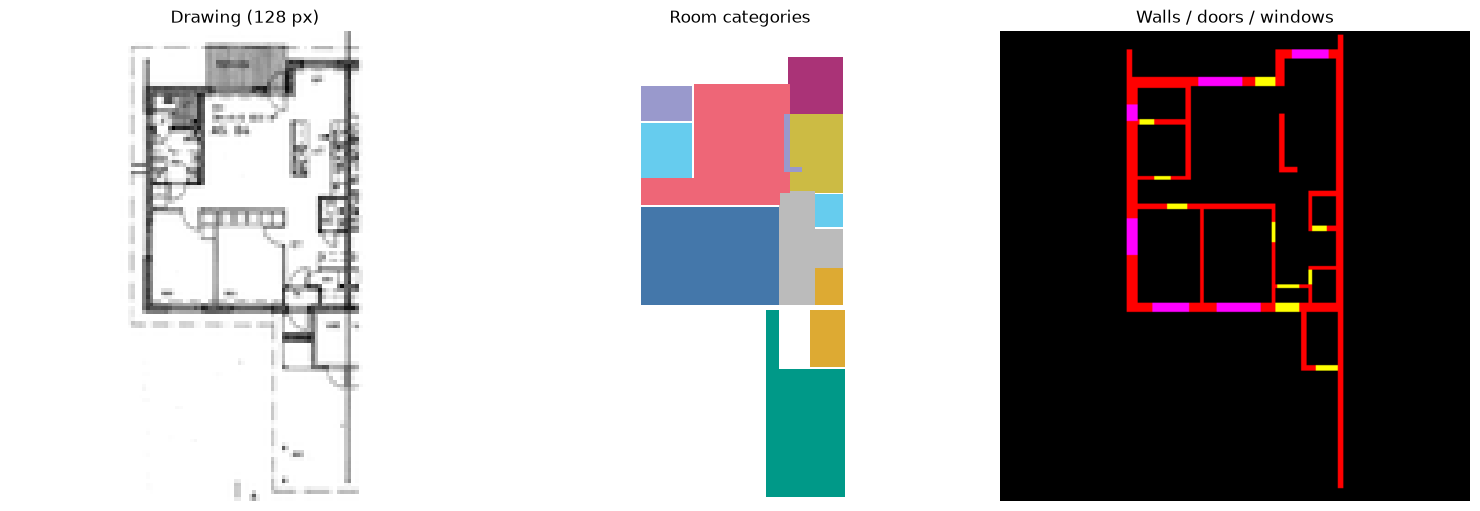

Dining          1
Kitchen         1
Entry           1
LivingRoom      1
CarPort         1
Undefined       2
Bedroom         2
Bath            2
Storage         1
Closet          1
DraughtLobby    1
Name: annotation count, dtype: int64

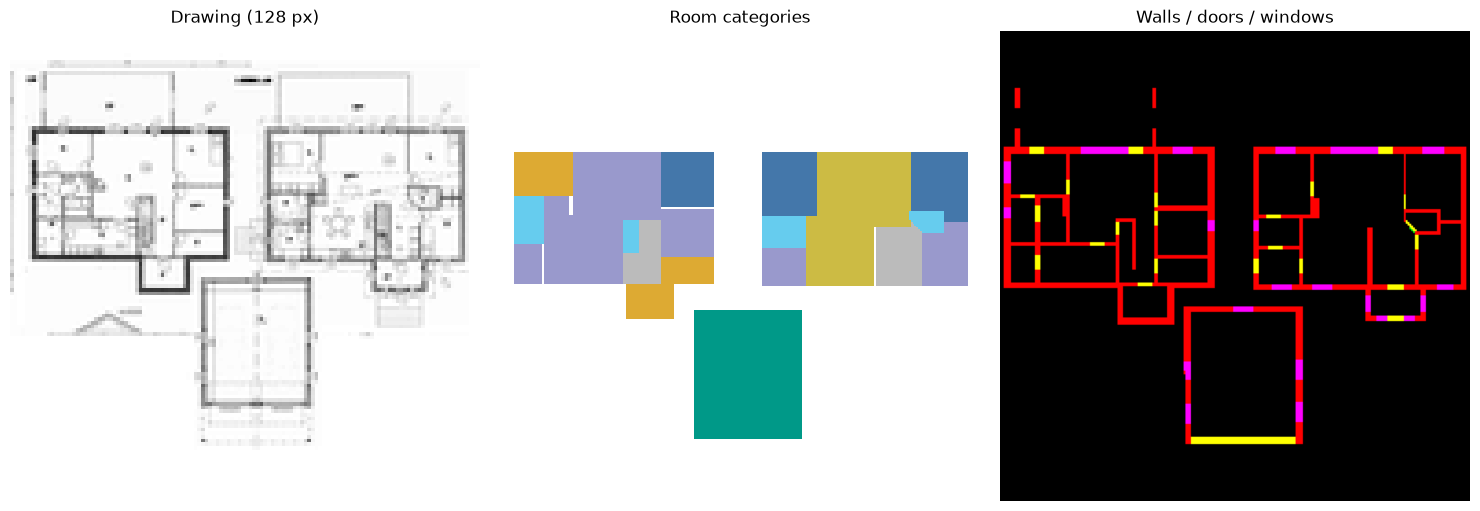

Garage            1
Storage           2
Hall              1
Bath              4
Den               1
Utility           2
TechnicalRoom     1
DressingRoom      1
Bedroom           3
RecreationRoom    1
Undefined         1
Office            1
Entry             1
Kitchen           1
Name: annotation count, dtype: int64

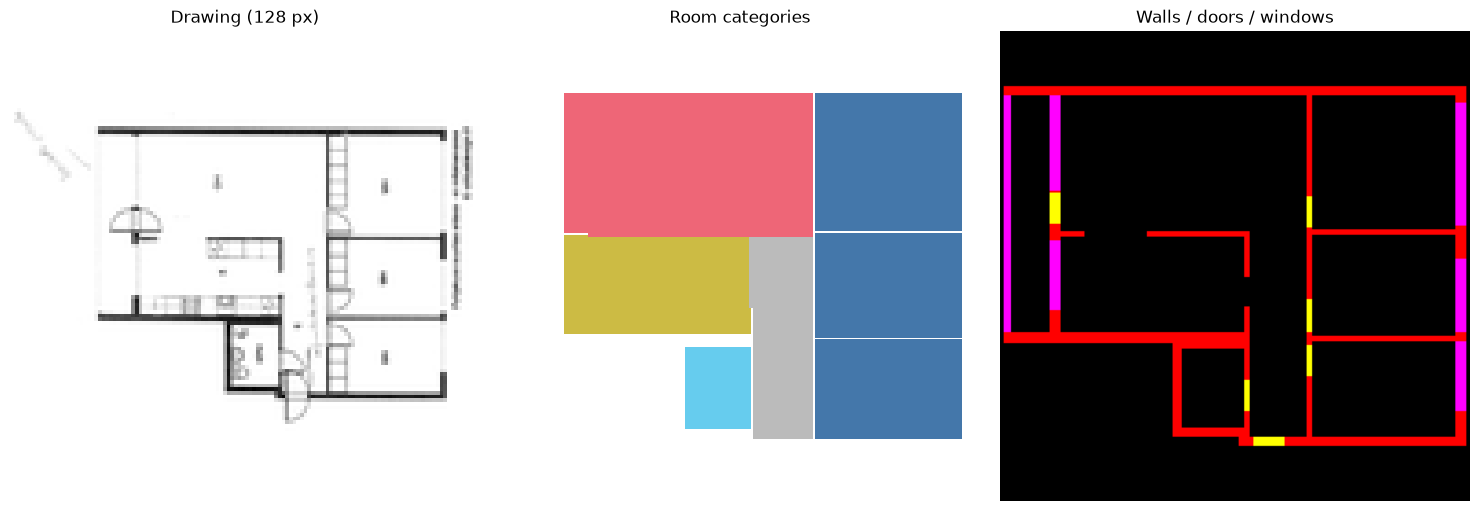

Kitchen       1
Entry         1
LivingRoom    1
Bedroom       3
Bath          1
Name: annotation count, dtype: int64

In [4]:
def inspect(layout):
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    if 'folder' in layout:
        axes[0].imshow(drawing(Path(layout['folder']).relative_to(DATASET_ROOT).as_posix()),cmap='gray')
    else: axes[0].text(.1,.5,'Synthetic example: no source drawing')
    axes[0].set_title('Drawing (128 px)')
    axes[1].imshow(layout['masks']['semantic'],cmap=ListedColormap(COLOURS),vmin=0,vmax=len(TYPES),interpolation='nearest')
    axes[1].set_title('Room categories')
    axes[2].imshow(np.stack([layout['masks'][k] for k in ('wall','door','window')],axis=-1).astype(float))
    axes[2].set_title('Walls / doors / windows')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()
    display(pd.Series(Counter(r['raw_type'] for r in layout['rooms']),name='annotation count'))

available=sorted(DATASET_ROOT.rglob('model.svg')) if DATASET_ROOT.exists() else []
print('Annotated plans:',len(available))
display(pd.DataFrame({'type':TYPES,'colour':COLOURS[1:]}))
if available:
    picks=np.random.default_rng(SEED).choice(len(available),min(20,len(available)),replace=False)
    shown=0
    for i in picks:  # Inspect all 20 before a full run.
        if shown==3: break
        try: inspect(load_plan(available[i].parent)); shown+=1
        except ValueError as error: print('Skipped',available[i].parent.name,'-',error)
else: print('Extract annotated data and set DATASET_ROOT. Synthetic checks below still run.')


## 4. Features and ranking

For each category we calculate its room count and fraction of internal room area. A **4 by 4 grid per category** describes its spatial distribution. Shape is log footprint width/height. These summaries are intentionally coarse: identical counts and similar grid occupancy do not guarantee equivalent circulation.

Standardisation uses training plans only, including their four orientations. Scale floors prevent nearly constant features from dominating. Each block contributes its mean absolute standardised difference, so the many grid features do not win merely because there are more of them. The winning rotation minimises the complete weighted score. Distances are ranking scores, not probabilities.


In [5]:
def features(layout,rotation=0):
    semantic=np.rot90(layout['masks']['semantic'],rotation)
    instance=np.rot90(layout['masks']['instance'],rotation)
    footprint=np.rot90(layout['masks']['footprint'],rotation)
    total=max(1,int((instance>0).sum()))
    counts=np.array([sum(r['type']==name for r in layout['rooms']) for name in TYPES],dtype=float)
    areas=np.array([(semantic==TYPE_ID[name]).sum()/total for name in TYPES])
    positions=[]
    for name in TYPES:
        for ys in np.array_split(np.arange(SIZE),4):
            for xs in np.array_split(np.arange(SIZE),4):
                positions.append((semantic[np.ix_(ys,xs)]==TYPE_ID[name]).sum()/total)
    y,x=np.where(footprint)
    return {'counts':counts,'areas':areas,'positions':np.array(positions),
            'shape':np.array([np.log((np.ptp(x)+1)/(np.ptp(y)+1))])}

class StructuralIndex:
    def __init__(self,feature_rows,splits):
        if len(feature_rows)!=len(splits): raise ValueError('Features and splits must align')
        train=np.asarray(splits)=='train'
        if not train.any(): raise ValueError('Need training plans to fit scales')
        self.values={}; self.center={}; self.scale={}; self.weights=dict(WEIGHTS)
        for block in self.weights:
            raw=np.array([[v[r][block] for r in range(4)] for v in feature_rows])
            training=raw[train].reshape(-1,raw.shape[-1])
            self.center[block]=training.mean(axis=0)
            self.scale[block]=np.maximum(training.std(axis=0),FLOORS[block])
            self.values[block]=(raw-self.center[block])/self.scale[block]
    def search(self,query,candidates=None,exclude=None,k=5):
        candidates=np.arange(len(self.values['counts'])) if candidates is None else np.asarray(candidates,dtype=int)
        if exclude is not None: candidates=candidates[candidates!=exclude]
        if not len(candidates): raise ValueError('No gallery candidates')
        q=features(query)
        parts={b:np.abs(self.values[b][candidates]-(q[b]-self.center[b])/self.scale[b]).mean(axis=-1) for b in self.weights}
        scores=sum(self.weights[b]*parts[b] for b in self.weights)
        rotations=scores.argmin(axis=1); rows=np.arange(len(candidates)); best=scores[rows,rotations]
        order=np.argsort(best,kind='stable')[:k]
        return pd.DataFrame([{'index':int(candidates[i]),'distance':float(best[i]),
            'rotation':int(rotations[i]*90),**{f'distance_{b}':float(parts[b][i,rotations[i]]) for b in self.weights}} for i in order])


## 5. Synthetic checks without the dataset

These invented rectangle layouts check identity, rotation, different arrangements and self-exclusion. A temporary SVG checks inherited transforms and room aliases. Passing these checks validates mechanics only; it provides no evidence of useful real-world matches.


Synthetic checks passed; not a retrieval-quality result.


,distance,rotation,distance_counts,distance_areas,distance_positions,distance_shape
index,,,,,,
0,0.000000,0,0.0,0.000000,0.00000,0.0
2,0.000000,270,0.0,0.000000,0.00000,0.0
1,0.206645,180,0.0,0.424264,0.30448,0.0


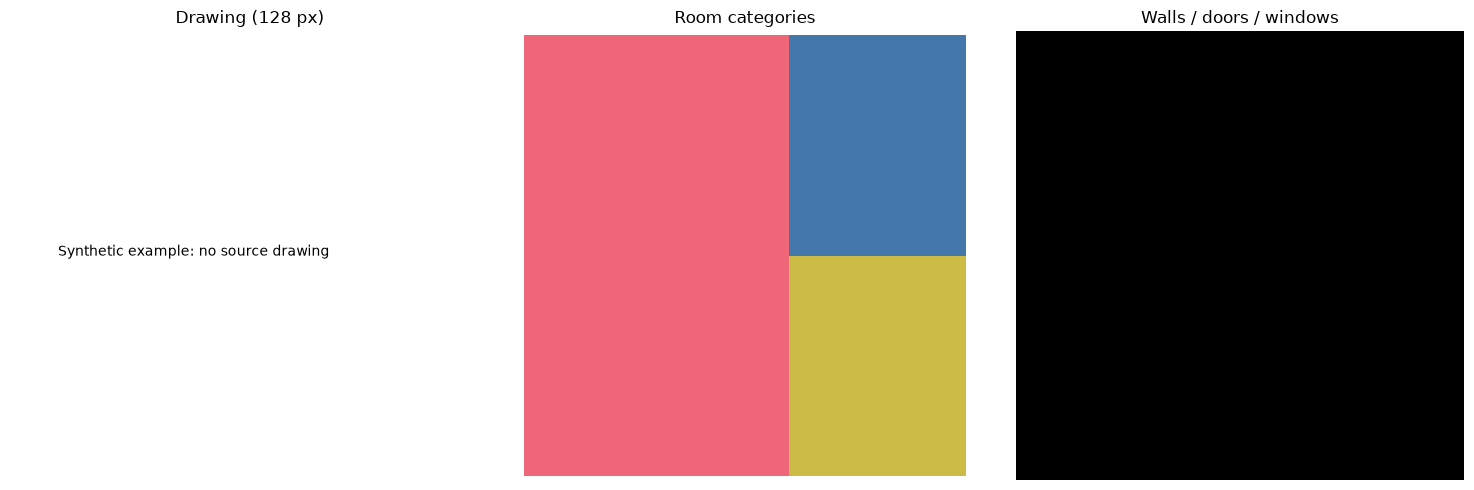

LivingRoom    1
Bedroom       1
Kitchen       1
Name: annotation count, dtype: int64

In [6]:
def synthetic(swapped=False):
    names=['LivingRoom','Bedroom','Kitchen'] if not swapped else ['Bedroom','LivingRoom','Kitchen']
    boxes=[(0,0,60,100),(60,0,100,50),(60,50,100,100)]
    records=[]
    for name,(x0,y0,x1,y1) in zip(names,boxes):
        records.append({'kind':'room','raw_type':name,'type':name,
            'points':np.array([[x0,y0],[x1,y0],[x1,y1],[x0,y1]],dtype=float)})
    return rasterize(records)
a,b=synthetic(),synthetic(True)
c=dict(a,masks={k:np.rot90(v) for k,v in a['masks'].items()})
demo_index=StructuralIndex([[features(p,r) for r in range(4)] for p in (a,b,c)],['train']*3)
demo=demo_index.search(a,k=3).set_index('index')
assert np.isclose(demo.loc[0,'distance'],0) and np.isclose(demo.loc[2,'distance'],0)
assert demo.loc[1,'distance']>0
assert 0 not in demo_index.search(a,exclude=0)['index'].tolist()
with tempfile.TemporaryDirectory() as directory:
    path=Path(directory)/'model.svg'
    path.write_text('<svg><g transform="translate(10 20)"><g class="Space HallWay">'
                    '<polygon points="0,0 20,0 20,20 0,20"/></g></g></svg>',encoding='utf-8')
    parsed=read_svg(path)
    assert parsed[0]['type']=='Circulation'
    np.testing.assert_allclose(parsed[0]['points'][0],[10,20])
print('Synthetic checks passed; not a retrieval-quality result.')
display(demo); inspect(a)


## 6. Build the collection with official splits

Set `RUN_COLLECTION=True` after inspecting real annotations. The dataset must include one each of `train.txt`, `val.txt` and `test.txt`. We preserve their membership and fail on missing or ambiguous matches. Parsing/rasterisation failures go to a CSV for review. Never substitute empty masks for failed plans.

Only compact features remain in memory; masks load on demand. The manifest retains source annotation hashes. A subset run is for debugging and is not comparable to a full benchmark. Generated artifacts include the manifest, feature arrays, fitted scales, configuration and failures.


In [7]:
def canonical(text):
    parts=text.strip().replace('\\','/').strip('/').split('/')
    if parts[-1] in ('model.svg','F1_scaled.png','F1_original.png'): parts=parts[:-1]
    return '/'.join(parts)

def official_splits():
    lookup={}
    for split in ('train','val','test'):
        files=list(DATASET_ROOT.rglob(f'{split}.txt'))
        if len(files)!=1: raise ValueError(f'Expected one {split}.txt, found {len(files)}')
        for line in files[0].read_text(encoding='utf-8-sig').splitlines():
            if not line.strip(): continue
            key=canonical(line)
            if key in lookup: raise ValueError(f'Duplicate split entry: {key}')
            lookup[key]=split
    return lookup

index=None; manifest=pd.DataFrame()
if RUN_COLLECTION:
    if not available: raise FileNotFoundError(f'No annotated plans under {DATASET_ROOT}')
    lookup=official_splits(); feature_rows=[]; rows=[]; failures=[]
    for svg in available[:MAX_PLANS]:
        relative=svg.parent.relative_to(DATASET_ROOT).as_posix()
        keys=[key for key in lookup if relative==key or relative.endswith('/'+key)]
        if len(keys)!=1: raise ValueError(f'No unique split for {relative}: {keys}')
        try:
            if keys[0] not in row_of: raise ValueError('Not among the 128 px drawings')
            layout=load_plan(svg.parent)
            feature_rows.append([features(layout,r) for r in range(4)])
            rows.append({'id':keys[0],'folder':str(svg.parent),'split':lookup[keys[0]],
                'rooms':len(layout['rooms']),'svg_sha256':hashlib.sha256(svg.read_bytes()).hexdigest()})
        except (ValueError,OSError,ET.ParseError) as error:
            failures.append({'id':relative,'error':str(error)})
        if (len(rows)+len(failures))%250==0: print('Processed:',len(rows)+len(failures))
    pd.DataFrame(failures,columns=['id','error']).to_csv(OUTPUT/'annotation_failures.csv',index=False)
    if not rows: raise RuntimeError('No valid plans. Inspect annotation_failures.csv')
    manifest=pd.DataFrame(rows); index=StructuralIndex(feature_rows,manifest['split'])
    manifest.to_csv(OUTPUT/'manifest.csv',index=False)
    np.savez_compressed(OUTPUT/'features.npz',**{f'values_{b}':index.values[b] for b in WEIGHTS},
        **{f'center_{b}':index.center[b] for b in WEIGHTS},**{f'scale_{b}':index.scale[b] for b in WEIGHTS})
    config={'version':'v3-structural-baseline-1','size':SIZE,'types':TYPES,'aliases':ALIASES,
        'weights':WEIGHTS,'floors':FLOORS,'rotations':[0,90,180,270],'grid':4,'seed':SEED,
        'partial_collection':MAX_PLANS is not None,'connectivity':False,
        'distance':'weighted block mean absolute standardized difference'}
    (OUTPUT/'config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
    display(manifest.groupby('split').agg(plans=('id','size'),median_rooms=('rooms','median')))
    print('Valid:',len(rows),'| failures:',len(failures),'; review failures before interpreting results.')
else: print('Collection disabled. Inspect samples, then set RUN_COLLECTION=True.')


Processed: 250


Processed: 500


Processed: 750


Processed: 1000


Processed: 1250


Processed: 1500


... (12 outputs left out)

Processed: 4750


Processed: 5000


,plans,median_rooms
split,,
test,373,9.0
train,3916,9.0
val,358,9.0


Valid: 4647 | failures: 353 ; review failures before interpreting results.


## 7. Search different plans

Validation and test queries search the **training gallery**. Exclude the query itself. During development use validation queries; reserve test queries until settings are frozen. Distance components explain whether programme or arrangement drives a match. The maps below are rotated into the best complete-plan alignment; original drawings keep their original orientation.


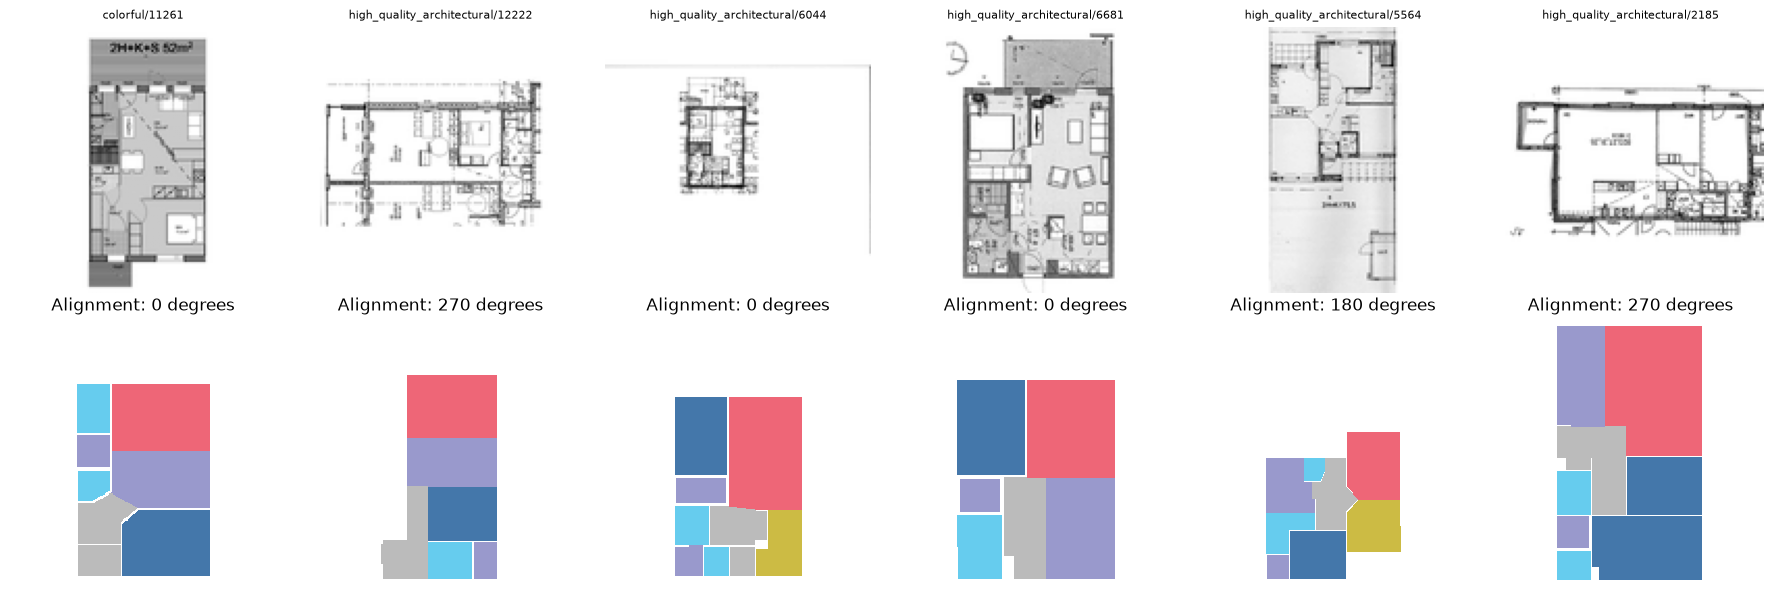

,index,distance,rotation,distance_counts,distance_areas,distance_positions,distance_shape,id
0,2029,0.171510,270,0.229944,0.113894,0.176028,0.093364,high_quality_architectural/12222
1,3721,0.229624,0,0.100000,0.341268,0.320766,0.030641,high_quality_architectural/6044
2,3923,0.233337,0,0.199627,0.056812,0.308697,0.386083,high_quality_architectural/6681
3,3580,0.235001,180,0.100000,0.351887,0.314257,0.089213,high_quality_architectural/5564
4,3105,0.238393,270,0.176649,0.257135,0.277525,0.229617,high_quality_architectural/2185


In [8]:
def retrieve(qi,k=5):
    query=load_plan(manifest.iloc[qi]['folder'])
    gallery=np.flatnonzero(manifest['split'].eq('train').to_numpy())
    matches=index.search(query,gallery,exclude=qi,k=k)
    matches['id']=manifest.iloc[matches['index']]['id'].to_numpy()
    return query,matches

def show_plans(ids,rotations=None):
    rotations=[0]*len(ids) if rotations is None else rotations
    by_id=manifest.set_index('id'); fig,axes=plt.subplots(2,len(ids),figsize=(3*len(ids),6),squeeze=False)
    for col,(pid,rotation) in enumerate(zip(ids,rotations)):
        layout=load_plan(by_id.loc[pid,'folder'])
        axes[0,col].imshow(drawing(pid),cmap='gray')
        axes[0,col].set_title(pid,fontsize=8)
        axes[1,col].imshow(np.rot90(layout['masks']['semantic'],rotation//90),
            cmap=ListedColormap(COLOURS),vmin=0,vmax=len(TYPES),interpolation='nearest')
        axes[1,col].set_title(f'Alignment: {rotation} degrees')
    for ax in axes.flat: ax.axis('off')
    plt.tight_layout(); plt.show()

if index is not None:
    validation=np.flatnonzero(manifest['split'].eq('val').to_numpy())
    if len(validation):
        qi=int(validation[0]); query,matches=retrieve(qi)
        show_plans([manifest.iloc[qi]['id']]+matches['id'].tolist(),[0]+matches['rotation'].tolist())
        display(matches)


## 8. v3: an autoencoder that turns a drawing into rooms

The search above uses the annotations, so it only works for the 5,000 plans of the dataset. An architect who uploads a plan has a drawing, not a `model.svg`. So we train a model that goes from the drawing to the rooms:
- **input:** the drawing at 128 px, cleaned down to its lines like in v2 (`01_autoencoder`, section 6);
- **code:** 128 numbers in the middle, like setup C;
- **output:** the room map of this notebook at 128 px, with one class per room type (10 types plus the background), and the walls.

The decoder has to draw where the bedrooms, bathrooms and the kitchen are, so the code has to hold the layout, not the pen. And because the input is only a drawing, it works on any uploaded plan. It's still an encoder and a decoder with a bottleneck, but the target isn't the input any more: it's the information the annotations add to the drawing, like the "constructed datasets" in Serjoscha's slides.

### 8.1 Inputs and targets

room maps for 4992 of 5000 plans


background     54.3%
Bedroom         8.9%
Bath            2.8%
Sauna           0.0%
Kitchen         5.7%
LivingRoom      9.2%
Dining          0.6%
Circulation     4.1%
Storage         1.6%
Garage          0.8%
Other          11.9%


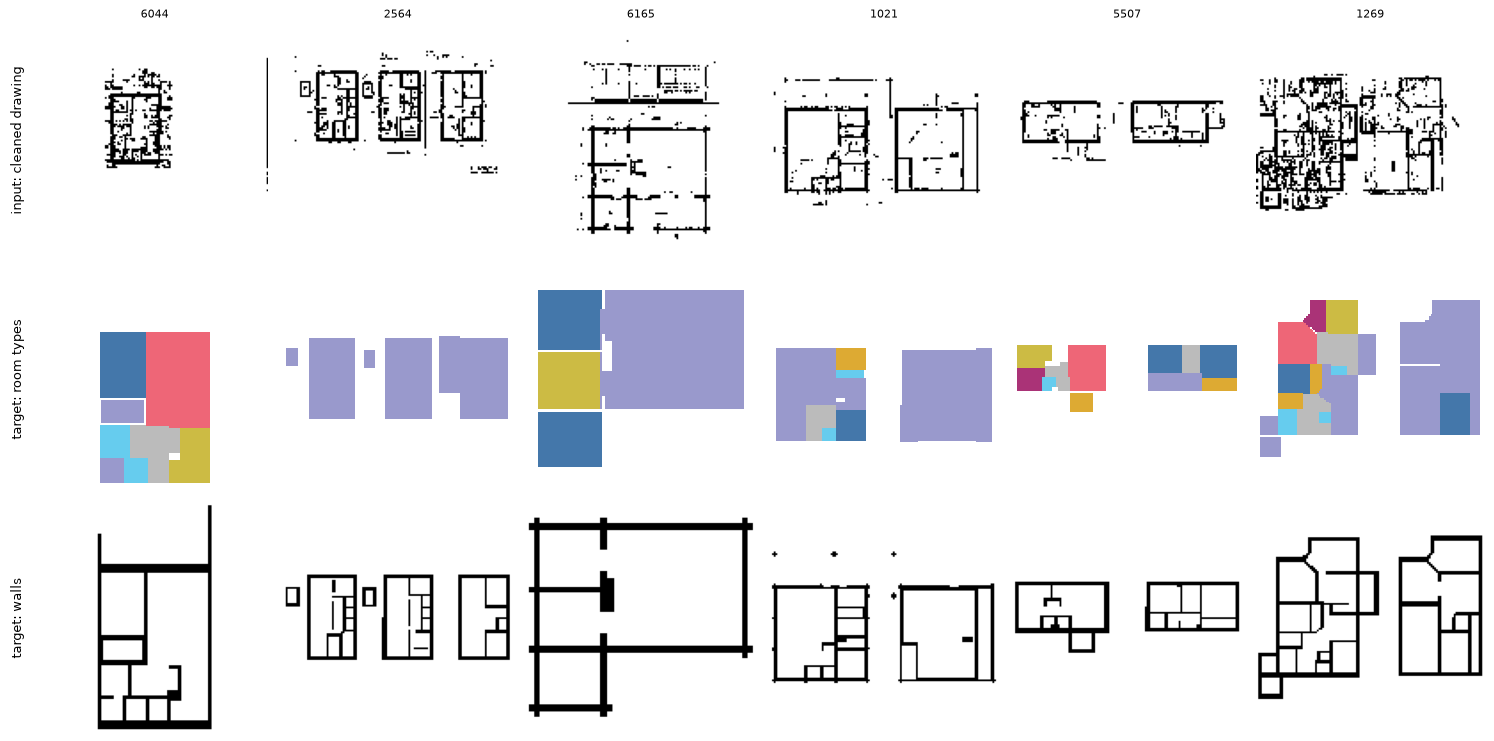

In [9]:
import warnings
#hide two harmless warnings from libraries (progress bars, umap's parallel jobs)
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', message='n_jobs value')
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from PIL import ImageFilter

V3_SIZE = 128
N_CLASSES = len(TYPES) + 1   #background + the 10 room types


def clean_plan(plan):
    #the same cleaning as v2 and the server: keep only the lines, the same way for every drawing
    image = Image.fromarray(plan)
    wide = image.filter(ImageFilter.MinFilter(5)).filter(ImageFilter.MaxFilter(5))
    lines = np.asarray(image, np.float32) - np.asarray(wide, np.float32)
    strong = lines[lines > 8]
    if strong.size < 20:
        return np.zeros_like(plan)
    return ((lines / np.percentile(strong, 90)) > 0.35).astype(np.uint8) * 255


def room_masks(folder):
    #the same steps as rasterize() above, straight at 128 px, and without failing when a tiny room disappears
    records = read_svg(Path(folder) / 'model.svg')
    rooms = [r for r in records if r['kind'] == 'room' and r['raw_type'] != 'Outdoor']
    structure = [r for r in records if r['kind'] in ('wall', 'door', 'window')]
    xy = np.concatenate([r['points'] for r in rooms + structure])
    lo, hi = xy.min(axis=0), xy.max(axis=0)
    scale = (V3_SIZE - 3) / float((hi - lo).max())
    offset = (V3_SIZE - (hi - lo) * scale) / 2 - lo * scale
    semantic = Image.new('L', (V3_SIZE, V3_SIZE), 0)
    wall = Image.new('L', (V3_SIZE, V3_SIZE), 0)
    for r in rooms:
        ImageDraw.Draw(semantic).polygon([tuple(p) for p in r['points'] * scale + offset], fill=TYPE_ID[r['type']])
    for r in structure:
        if r['kind'] == 'wall':
            ImageDraw.Draw(wall).polygon([tuple(p) for p in r['points'] * scale + offset], fill=1)
    counts = np.array([sum(r['type'] == name for r in rooms) for name in TYPES])
    return np.asarray(semantic, np.uint8), np.asarray(wall, np.uint8), counts


X_v3 = torch.from_numpy(np.stack([clean_plan(plan) for plan in data['images']])).float().div(255).unsqueeze(1)
rooms_y = np.zeros((len(plan_ids), V3_SIZE, V3_SIZE), np.uint8)
walls_y = np.zeros_like(rooms_y)
room_counts = np.zeros((len(plan_ids), len(TYPES)), int)
has_rooms = np.zeros(len(plan_ids), bool)
for i, pid in enumerate(plan_ids):
    try:
        rooms_y[i], walls_y[i], room_counts[i] = room_masks(DATASET_ROOT / pid)
        has_rooms[i] = True
    except (ValueError, OSError, ET.ParseError):
        pass   #no usable annotation: the plan stays in the collection, but isn't used for training or scoring
print(f'room maps for {has_rooms.sum()} of {len(plan_ids)} plans')
shares = np.bincount(rooms_y[has_rooms].ravel(), minlength=N_CLASSES) / rooms_y[has_rooms].size
print(pd.Series(shares, index=['background', *TYPES]).map('{:.1%}'.format).to_string())

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for col, i in enumerate(np.flatnonzero(has_rooms)[:6]):
    axes[0, col].imshow(1 - X_v3[i, 0], cmap='gray')
    axes[1, col].imshow(rooms_y[i], cmap=ListedColormap(COLOURS), vmin=0, vmax=len(TYPES), interpolation='nearest')
    axes[2, col].imshow(walls_y[i], cmap='gray_r')
    axes[0, col].set_title(plan_ids[i].split('/')[-1], fontsize=8)
for ax in axes.flat: ax.axis('off')
for row, label in enumerate(['input: cleaned drawing', 'target: room types', 'target: walls']):
    axes[row, 0].text(-10, 64, label, rotation=90, va='center', ha='right', fontsize=9)
plt.tight_layout()
plt.savefig(PROJECT / '01_autoencoder/figures/13_v3_inputs_targets.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.2 The model and its training
The encoder is the one of setup C. The decoder ends with 12 channels: 11 for the room classes, scored with cross-entropy, and 1 for the walls, scored with binary cross-entropy. Same split, seed, epochs, batches and learning rate as in `01_autoencoder`, on the CPU. Plans without a usable annotation aren't used for training.

In [10]:
class DrawingToRooms(nn.Module):
    #encoder of setup C (128 -> 8 px -> code of 128 numbers); the decoder draws 11 room classes + the walls
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 64, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, N_CLASSES + 1, 3, stride=2, padding=1, output_padding=1),
        )

    def forward(self, x):
        code = self.encoder(x)
        return code, self.decoder(code)


def v3_loss(output, rooms, walls):
    return (nn.functional.cross_entropy(output[:, :N_CLASSES], rooms.long())
            + nn.functional.binary_cross_entropy_with_logits(output[:, N_CLASSES], walls.float()))


@torch.no_grad()
def encode_v3(model, X, batch_size=200):
    #only the codes: the 12 output channels of all 5,000 plans would need about 4 GB
    model.eval()
    return torch.cat([model.encoder(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])


@torch.no_grad()
def run_v3(model, X, batch_size=200):
    model.eval()
    codes, outputs = zip(*[model(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])
    return torch.cat(codes), torch.cat(outputs)


R_all, W_all = torch.from_numpy(rooms_y), torch.from_numpy(walls_y)
train_rows = np.flatnonzero((plan_splits == 'train') & has_rooms)
val_rows = np.flatnonzero((plan_splits == 'val') & has_rooms)
test_rows = np.flatnonzero((plan_splits == 'test') & has_rooms)

torch.manual_seed(SEED)
model_v3 = DrawingToRooms()
optimizer = torch.optim.Adam(model_v3.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(X_v3[train_rows], R_all[train_rows], W_all[train_rows]), batch_size=64, shuffle=True)
history_v3 = []
start = time.time()
for epoch in range(1, 21):
    model_v3.train()
    total = 0.0
    for x, r, w in loader:
        loss = v3_loss(model_v3(x)[1], r, w)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(x)
    _, val_output = run_v3(model_v3, X_v3[val_rows])
    history_v3.append({'epoch': epoch, 'train loss': total / len(train_rows),
                       'validation loss': v3_loss(val_output, R_all[val_rows], W_all[val_rows]).item()})
print(f'trained on {len(train_rows)} plans in {time.time() - start:.0f} s')
pd.DataFrame(history_v3).set_index('epoch').iloc[[0, 4, 9, 14, 19]]

trained on 4194 plans in 420 s


,train loss,validation loss
epoch,,
1,2.182481,1.819007
5,1.539558,1.493336
10,1.359374,1.361926
15,1.238919,1.355243
20,1.073977,1.446864


### 8.3 Does it find the rooms in a drawing?

footprint: 68% overlap (IoU) between the predicted and the true plan area
room type of the pixels inside the plan: 29% right, against 27% for always answering "Other"
Bedroom        30%
Bath           14%
Sauna           0%
Kitchen         5%
LivingRoom     48%
Dining          0%
Circulation    30%
Storage         0%
Garage          0%
Other          36%


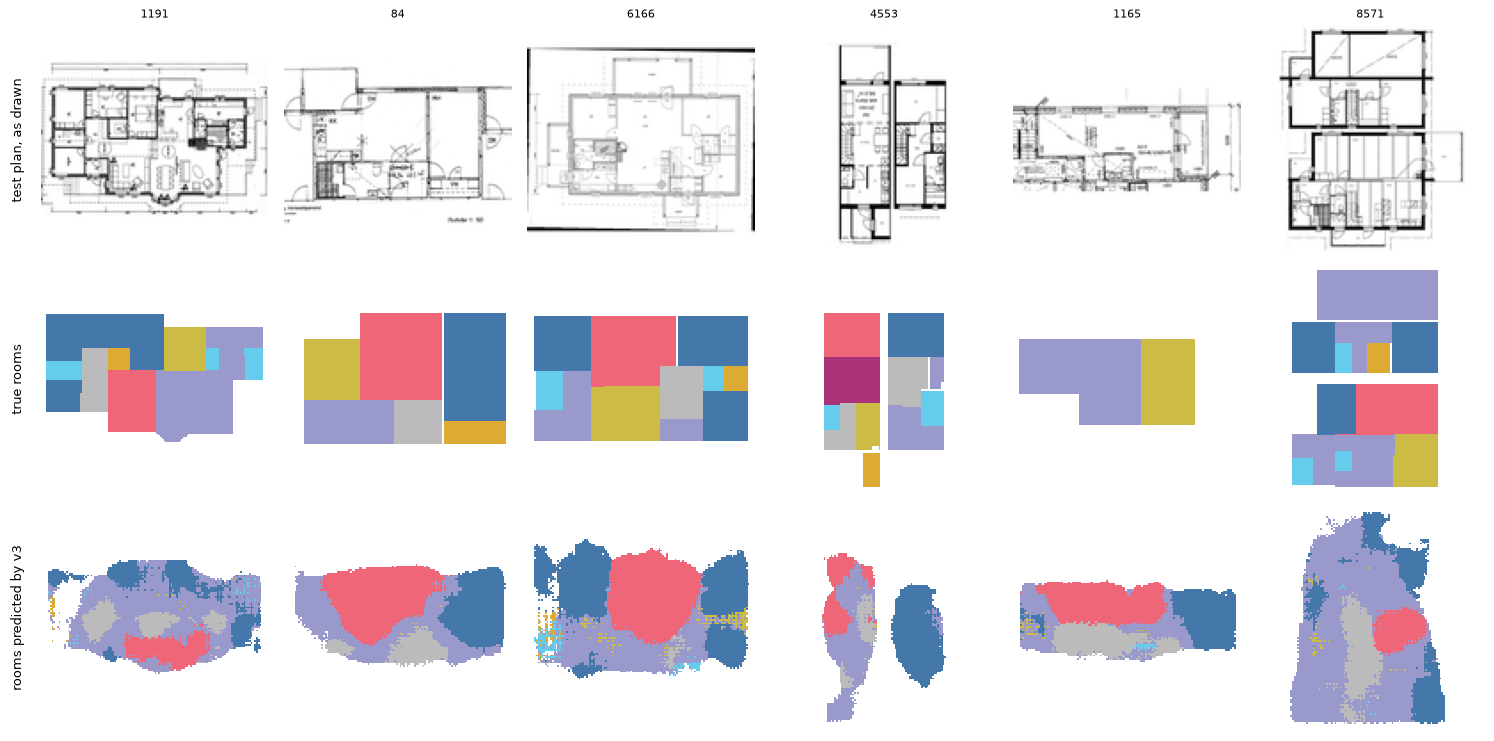

In [11]:
_, test_output = run_v3(model_v3, X_v3[test_rows])
predicted = test_output[:, :N_CLASSES].argmax(dim=1)
truth = R_all[test_rows].long()
inside = truth > 0
footprint_iou = ((predicted > 0) & inside).sum() / ((predicted > 0) | inside).sum()
type_accuracy = (predicted[inside] == truth[inside]).float().mean()
majority_type = truth[inside].mode().values.item()
majority_accuracy = (truth[inside] == majority_type).float().mean()
print(f'footprint: {footprint_iou:.0%} overlap (IoU) between the predicted and the true plan area')
print(f'room type of the pixels inside the plan: {type_accuracy:.0%} right, '
      f'against {majority_accuracy:.0%} for always answering "{(["background", *TYPES])[majority_type]}"')
per_type = pd.Series({name: (predicted[truth == TYPE_ID[name]] == TYPE_ID[name]).float().mean().item()
                      for name in TYPES if (truth == TYPE_ID[name]).any()}, name='pixels found')
print(per_type.map('{:.0%}'.format).to_string())

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for col, k in enumerate([0, 40, 80, 120, 160, 200]):
    i = test_rows[k]
    axes[0, col].imshow(drawing(plan_ids[i]), cmap='gray')
    axes[1, col].imshow(rooms_y[i], cmap=ListedColormap(COLOURS), vmin=0, vmax=len(TYPES), interpolation='nearest')
    axes[2, col].imshow(predicted[k], cmap=ListedColormap(COLOURS), vmin=0, vmax=len(TYPES), interpolation='nearest')
    axes[0, col].set_title(plan_ids[i].split('/')[-1], fontsize=8)
for ax in axes.flat: ax.axis('off')
for row, label in enumerate(['test plan, as drawn', 'true rooms', 'rooms predicted by v3']):
    axes[row, 0].text(-10, 64, label, rotation=90, va='center', ha='right', fontsize=9)
plt.tight_layout()
plt.savefig(PROJECT / '01_autoencoder/figures/14_v3_predicted_rooms.png', dpi=150, bbox_inches='tight')
plt.show()

- The validation loss stops improving after epoch 15 and rises again at epoch 20 (1.36 to 1.45): from there the model starts to learn the training plans by heart.
- It finds the plan: its predicted area overlaps the true one by 68%.
- It puts the big rooms roughly in the right places: 48% of the living-room pixels and 30% of the bedroom pixels, like in plans 84 and 6166, with the living room in the middle and the bedrooms at the sides.
- It hardly finds the small rooms: bathrooms 14%, kitchens 5%, storage and saunas never. Over all the pixels inside a plan it gets the room type right 29% of the time, only a little better than always answering "Other" (27%).

At 128 px and after the cleaning, the bathtubs, the kitchen counters and the room names are mostly gone: the model sees the walls, but not what the rooms are for.

### 8.4 Are the neighbours similar homes?
This is the question v2 couldn't answer. For every test plan with annotations we take its 5 nearest plans in the training gallery, in four ways:
- **v2:** the codes of `01_autoencoder`, trained to redraw the cleaned lines;
- **v3:** the codes of the model above, trained to find the rooms;
- **structural:** this notebook's search on the true annotations. A user's upload doesn't have them, so this is the best case, not something the app can do;
- **random:** 5 random plans, the floor.

Then we judge the neighbours with the annotations: the structural distance of this notebook (lower = more alike in room programme and arrangement), how often they have the same number of bedrooms and of bathrooms, and how far their number of rooms is.

373 test queries, gallery of 3916 training plans


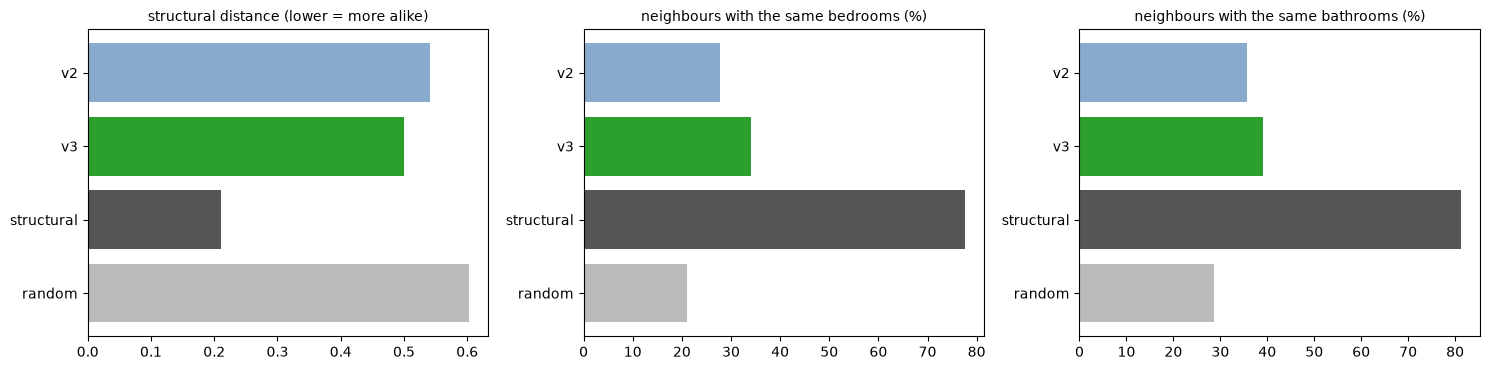

,structural distance,same bedrooms,same bathrooms,rooms off by
method,,,,
v2,0.54,28%,36%,4.7
v3,0.50,34%,39%,3.7
structural,0.21,78%,81%,1.4
random,0.60,21%,29%,5.7


In [12]:
from huggingface_hub import hf_hub_download

HF_REPO = 'iaac-maai/hackathon-team6-cubicasa-ae'
v2_file = PROJECT / '01_autoencoder/model_app/collection_codes_v2.npy'
codes_v2 = torch.from_numpy(np.load(v2_file if v2_file.exists() else hf_hub_download(HF_REPO, 'collection_codes_v2.npy')))
codes_v3 = encode_v3(model_v3, X_v3)

#the same gallery and queries for every method: plans with annotations that are also in this notebook's index
manifest_row = {pid: k for k, pid in enumerate(manifest['id'])}
gallery = np.array([i for i in train_rows if plan_ids[i] in manifest_row])
queries = np.array([i for i in test_rows if plan_ids[i] in manifest_row])
gallery_manifest = np.array([manifest_row[plan_ids[i]] for i in gallery])
rng = np.random.default_rng(SEED)

bed, bath = TYPES.index('Bedroom'), TYPES.index('Bath')
rows = []
for q in queries:
    query_layout = load_plan(manifest.iloc[manifest_row[plan_ids[q]]]['folder'])
    neighbours = {
        'v2': gallery[torch.cdist(codes_v2[q:q + 1], codes_v2[gallery])[0].topk(5, largest=False).indices.numpy()],
        'v3': gallery[torch.cdist(codes_v3[q:q + 1], codes_v3[gallery])[0].topk(5, largest=False).indices.numpy()],
        'structural': np.array([gallery[np.flatnonzero(gallery_manifest == k)[0]] for k in index.search(query_layout, gallery_manifest, k=5)['index']]),
        'random': rng.choice(gallery, 5, replace=False),
    }
    for method, found in neighbours.items():
        scored = index.search(query_layout, [manifest_row[plan_ids[i]] for i in found], k=5)
        rows.append({'method': method,
                     'structural distance': scored['distance'].mean(),
                     'same bedrooms': (room_counts[found, bed] == room_counts[q, bed]).mean(),
                     'same bathrooms': (room_counts[found, bath] == room_counts[q, bath]).mean(),
                     'rooms off by': np.abs(room_counts[found].sum(1) - room_counts[q].sum()).mean()})

relevance = pd.DataFrame(rows).groupby('method', sort=False).mean()
print(f'{len(queries)} test queries, gallery of {len(gallery)} training plans')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
colours = {'random': '#bbbbbb', 'v2': '#88aacc', 'v3': '#2ca02c', 'structural': '#555555'}
for ax, column, label in zip(axes, ['structural distance', 'same bedrooms', 'same bathrooms'],
                             ['structural distance (lower = more alike)', 'neighbours with the same bedrooms (%)', 'neighbours with the same bathrooms (%)']):
    values = relevance[column] * (1 if column == 'structural distance' else 100)
    ax.barh(values.index, values.values, color=[colours[m] for m in values.index])
    ax.invert_yaxis()
    ax.set_title(label, fontsize=10)
plt.tight_layout()
plt.savefig(PROJECT / '01_autoencoder/figures/15_v3_relevance.png', dpi=150, bbox_inches='tight')
plt.show()
relevance.style.format({'structural distance': '{:.2f}', 'same bedrooms': '{:.0%}', 'same bathrooms': '{:.0%}', 'rooms off by': '{:.1f}'})

| | v2 | v3 | structural | random |
|---|---|---|---|---|
| Structural distance | 0.54 | **0.50** | 0.21 | 0.60 |
| Same number of bedrooms | 28% | **34%** | 78% | 21% |
| Same number of bathrooms | 36% | **39%** | 81% | 29% |
| Rooms off by | 4.7 | **3.7** | 1.4 | 5.7 |

v3 beats v2 on every measure, but by a little. v2 was only somewhat better than random plans at finding similar homes, and v3 adds about as much again. The structural search on the true annotations is far ahead: that's how much is left to gain if the model learned to read the rooms better.

We also tried two changes: stopping the training at the best validation epoch (14), and giving the model the plans as drawn instead of cleaned, so it could see the bathtubs and the text. The neighbours stayed within one point of the numbers above, so we kept the simplest version.

### 8.5 The same queries with v2 and v3
For three test plans: the plan, then the first three matches of v2 and of v3, each as drawn and as rooms.

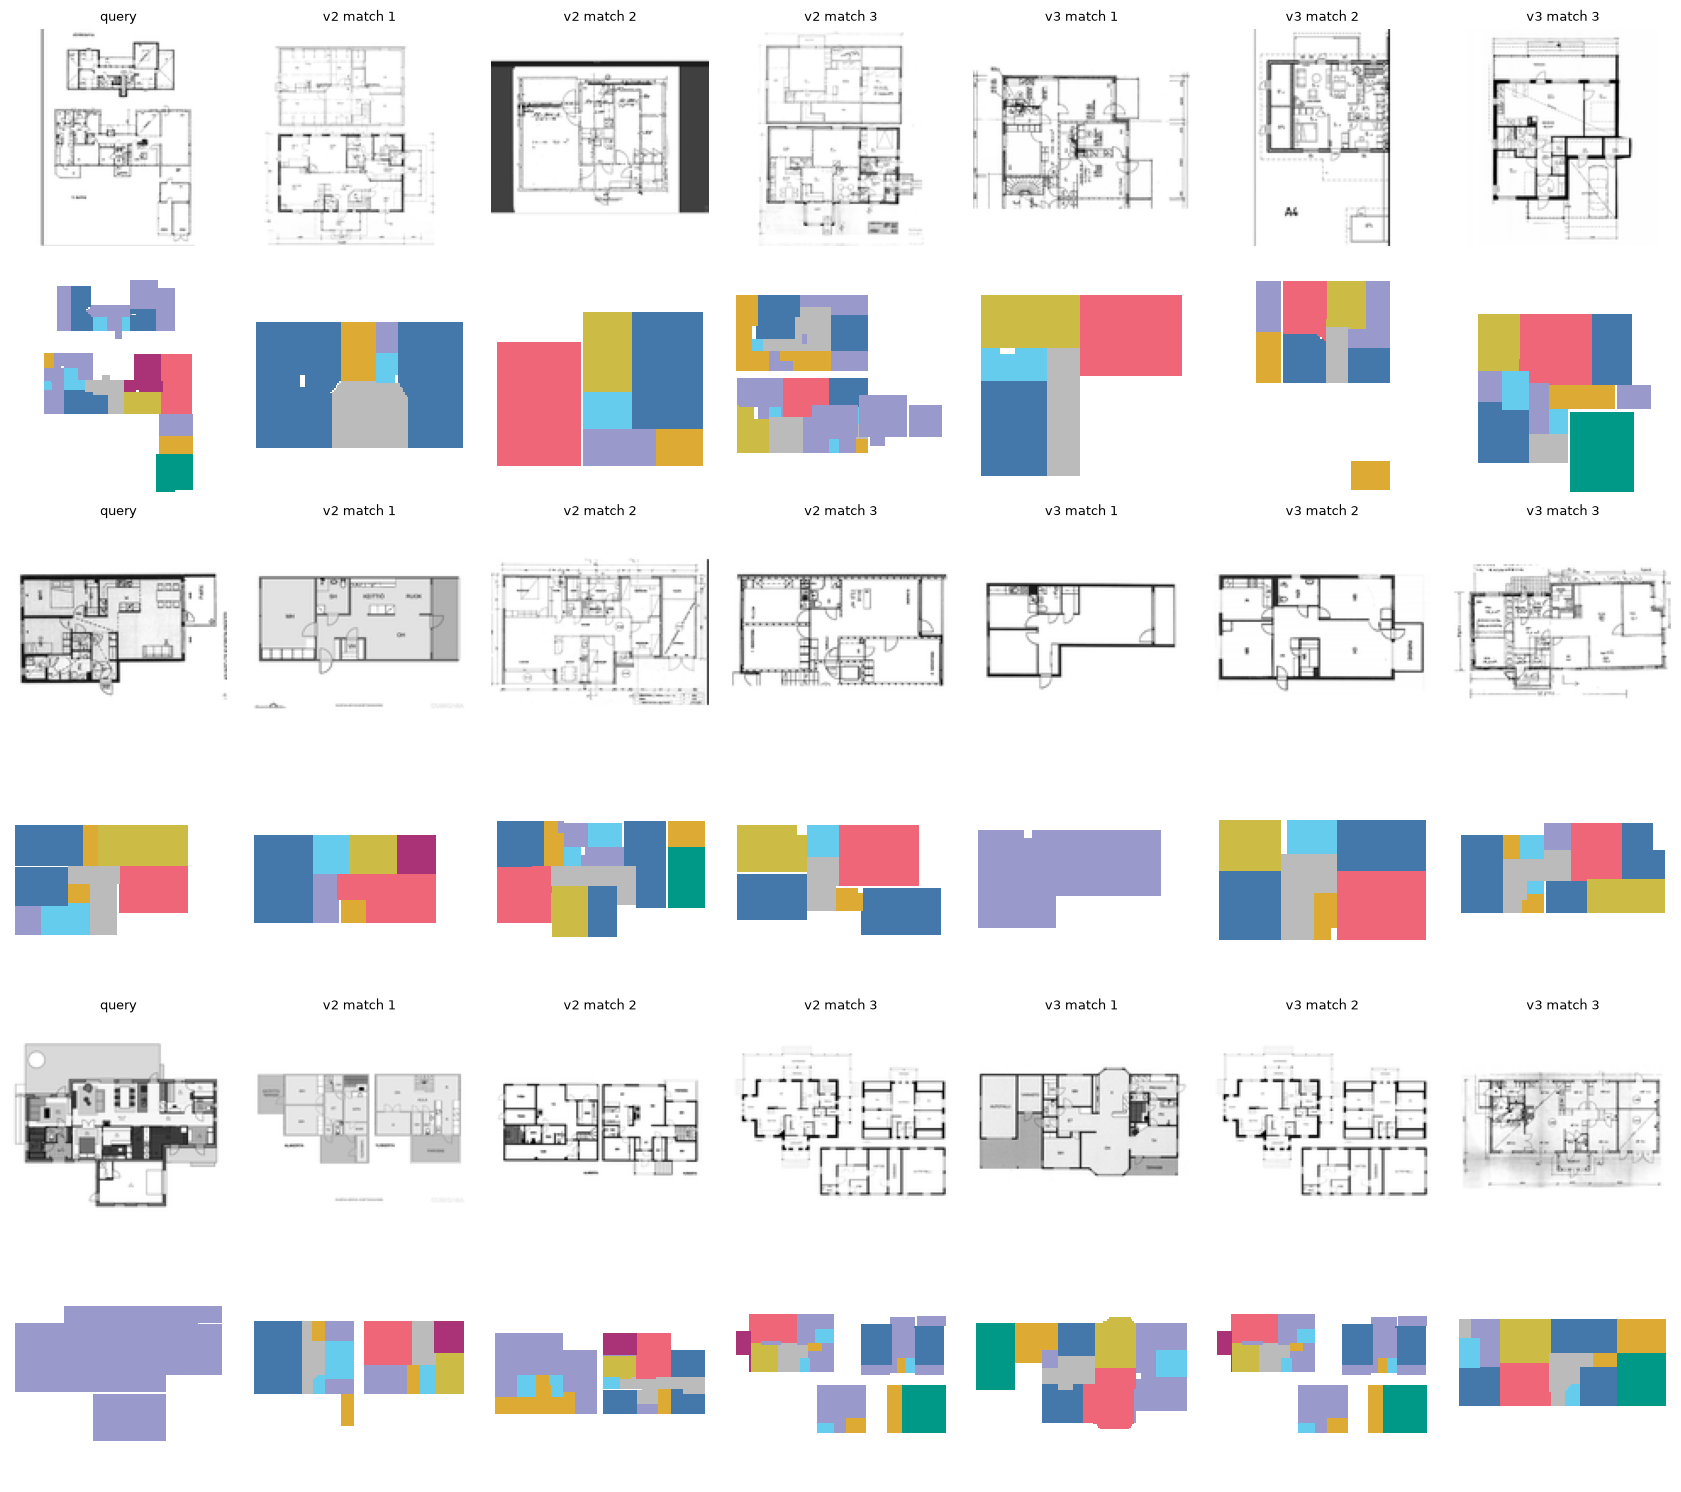

In [13]:
fig, axes = plt.subplots(6, 7, figsize=(17, 15))
for block, k in enumerate([10, 150, 300]):
    q = queries[k]
    picks = [q]
    for codes in (codes_v2, codes_v3):
        picks += list(gallery[torch.cdist(codes[q:q + 1], codes[gallery])[0].topk(3, largest=False).indices.numpy()])
    titles = ['query'] + [f'v2 match {n}' for n in (1, 2, 3)] + [f'v3 match {n}' for n in (1, 2, 3)]
    for col, (i, title) in enumerate(zip(picks, titles)):
        axes[2 * block, col].imshow(drawing(plan_ids[i]), cmap='gray')
        axes[2 * block + 1, col].imshow(rooms_y[i], cmap=ListedColormap(COLOURS), vmin=0, vmax=len(TYPES), interpolation='nearest')
        axes[2 * block, col].set_title(title, fontsize=9)
for ax in axes.flat: ax.axis('off')
plt.tight_layout()
plt.savefig(PROJECT / '01_autoencoder/figures/16_v2_v3_matches.png', dpi=150, bbox_inches='tight')
plt.show()

The examples show why the gain is small. In the second query, a flat with the bedrooms on one side and the living room on the other, both v2 and v3 find flats with bedrooms, a kitchen, a bathroom and a living room in a similar split. The third query is a colour plan whose annotations call almost everything "Other", so its room map says little about it. One v3 match of the second query has the same problem. About a quarter of the room pixels in CubiCasa5K are labelled "Other" (27%).

### 8.6 An atlas of layouts
All 5,000 plans placed on a map by their v3 codes, drawn as their room maps (colours as in the legend of section 3).

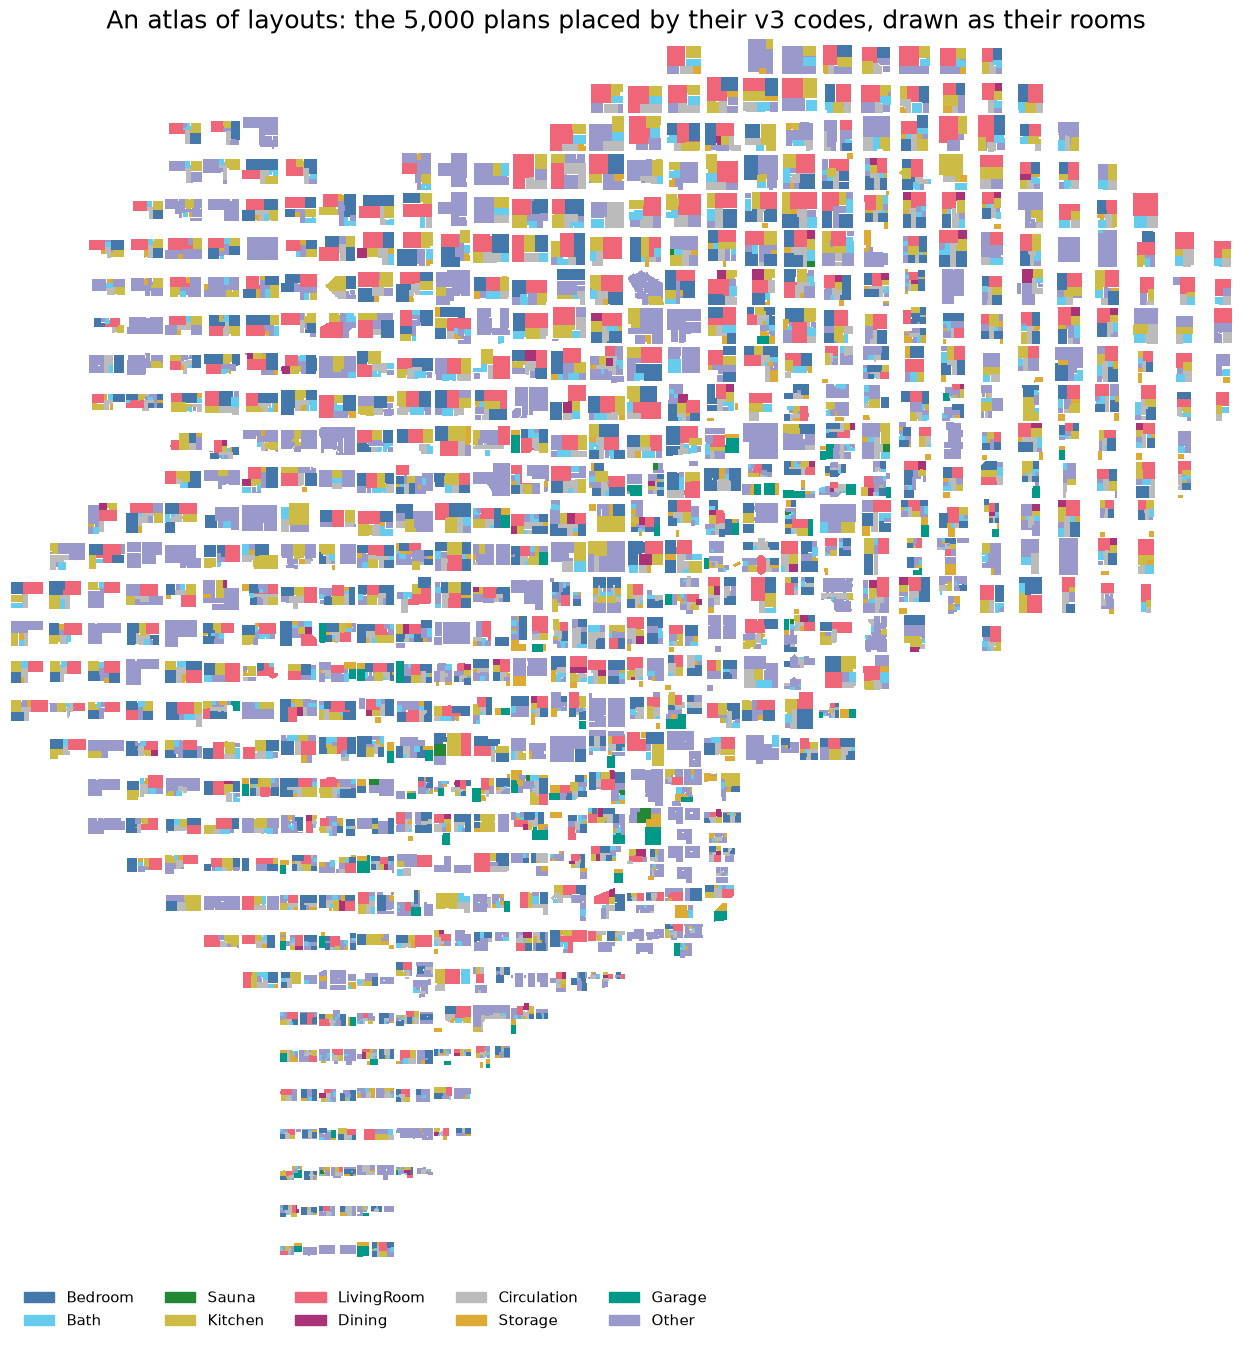

In [14]:
import umap

atlas_v3_xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(codes_v3.numpy())
atlas_v3_xy = (atlas_v3_xy - atlas_v3_xy.min(axis=0)) / (atlas_v3_xy.max(axis=0) - atlas_v3_xy.min(axis=0))

GRID = 32
room_colours = ListedColormap(COLOURS)
fig, ax = plt.subplots(figsize=(16, 16))
for row in range(GRID):
    for col in range(GRID):
        centre = np.array([(col + 0.5) / GRID, (row + 0.5) / GRID])
        distances = np.linalg.norm(atlas_v3_xy - centre, axis=1)
        nearest = distances.argmin()
        if distances[nearest] < 0.7 / GRID and has_rooms[nearest]:
            ax.imshow(room_colours(rooms_y[nearest] / len(TYPES)), interpolation='nearest',
                      extent=(col / GRID, (col + 1) / GRID, row / GRID, (row + 1) / GRID))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOURS[1:]]
ax.legend(handles, TYPES, loc='lower left', ncol=5, fontsize=11, frameon=False, bbox_to_anchor=(0, -0.06))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')
ax.set_title('An atlas of layouts: the 5,000 plans placed by their v3 codes, drawn as their rooms', fontsize=18)
plt.savefig(PROJECT / '01_autoencoder/figures/17_layout_atlas_v3.png', dpi=150, bbox_inches='tight')
plt.show()

The colours show the programme of every plan. At the top right are the compact plans with a big living room (red) and two or three bedrooms (blue). On the left are the wide houses, and at the bottom the small, wide drawings with many little rooms, often several homes on one sheet. Plans whose annotations are mostly "Other" (lilac) are spread all over the map.

This is the map we want in the app: an uploaded plan lands among homes with a similar programme, not among plans drawn with the same pen.

### 8.7 Saving v3 for the server
The ONNX file has two outputs: the code, for the search, and the 12 channels of the decoder, so the server can show the rooms it sees in an uploaded plan. It goes next to v1 and v2 in `01_autoencoder/model_app/` and `01_autoencoder/models/`, with the codes of the 5,000 plans, their places on the atlas and their true room maps (`collection_rooms_128.npz`), so the server can show the rooms of every match.

In [15]:
import logging
import shutil
import onnxruntime as ort

logging.getLogger('torch.onnx').setLevel(logging.ERROR)
MODEL_APP = PROJECT / '01_autoencoder/model_app'
MODELS = PROJECT / '01_autoencoder/models'

model_v3 = model_v3.cpu().eval()
torch.save(model_v3.state_dict(), MODELS / 'floorplan_ae_v3.pt')
torch.onnx.export(model_v3, (X_v3[:1],), MODEL_APP / 'floorplan_ae_v3.onnx', input_names=['image'],
                  output_names=['code', 'rooms'], dynamic_shapes={'x': {0: torch.export.Dim('batch')}},
                  external_data=False, verbose=False)
np.save(MODEL_APP / 'collection_codes_v3.npy', codes_v3.numpy().astype(np.float32))
np.save(MODEL_APP / 'atlas_v3_xy.npy', atlas_v3_xy.astype(np.float32))
#the true room maps of the 5,000 plans, so the server can show the rooms of every match
np.savez_compressed(MODEL_APP / 'collection_rooms_128.npz', rooms=rooms_y, has_rooms=has_rooms)

config_v3 = {
    'architecture': 'encoder of setup C, code 128; decoder draws 11 room classes and the walls',
    'latent_dim': 128,
    'image_size': V3_SIZE,
    'preprocessing': 'greyscale, invert (walls bright, background dark), pad to a square with black, resize to 128x128 '
                     '(Lanczos); then cleaned: keep only lines thinner than 5 px (plan minus its 5x5 opening), scale by '
                     'the 90th percentile of its lines, threshold 0.35; pixels 0-1',
    'outputs': {'code': 'N x 128', 'rooms': 'N x 12 x 128 x 128: channels 0-10 room classes (argmax), channel 11 walls (logit)'},
    'room_classes': ['background', *TYPES],
    'room_colours': COLOURS,
    'similarity': 'Euclidean distance between codes; smaller = more similar',
    'collection': 'CubiCasa5K, all 5,000 plans (train + validation + test)',
    'test_same_bedrooms': round(float(relevance.loc['v3', 'same bedrooms']), 3),
    'test_room_type_accuracy': round(float(type_accuracy), 3),
}
(MODEL_APP / 'floorplan_ae_v3_config.json').write_text(json.dumps(config_v3, indent=2))

session = ort.InferenceSession(MODEL_APP / 'floorplan_ae_v3.onnx')
onnx_code, _ = session.run(None, {'image': X_v3[test_rows[:5]].numpy()})
print('same codes as PyTorch:', np.allclose(codes_v3[test_rows[:5]].numpy(), onnx_code, atol=1e-4))

for name in ['floorplan_ae_v3.onnx', 'floorplan_ae_v3_config.json', 'collection_codes_v3.npy', 'atlas_v3_xy.npy',
             'collection_rooms_128.npz']:
    shutil.copy(MODEL_APP / name, MODELS / name)
for name in ['13_v3_inputs_targets.png', '14_v3_predicted_rooms.png', '15_v3_relevance.png',
             '16_v2_v3_matches.png', '17_layout_atlas_v3.png']:
    shutil.copy(PROJECT / '01_autoencoder/figures' / name, MODELS / 'figures' / name)
print('v3 saved in', MODEL_APP, 'and', MODELS)

same codes as PyTorch: True
v3 saved in /Users/luca_obejdeanu/Downloads/hackathon-team6-floorplan-similarity/01_autoencoder/model_app and /Users/luca_obejdeanu/Downloads/hackathon-team6-floorplan-similarity/01_autoencoder/models


## 9. Create a human review benchmark

Start with up to **30 validation queries**, sampled reproducibly across room-count bands. Inspect their typological diversity and document any manual changes before tuning weights. Candidates pool structural top five, five random training plans and optional v2 top five.

For a fair v2 comparison, export `v2_rankings.csv` under `OUTPUT`, with columns `query_id,candidate_id,rank`. V2 must use exactly the selected queries and the same training gallery. No automatic v2 inference runs here; its weights are not stored locally in this repository.

The review CSV hides retrieval methods/ranks and shuffles pairs. Label **2 = strong match, 1 = partial match, 0 = poor match**. Consider room programme, arrangement and circulation. Blank means unreviewed. Label all pooled candidates, not just attractive matches. Reruns preserve existing labels. Keep this ignored data folder backed up separately if you want to preserve your judgements.


In [16]:
def make_review_pool(split='val',n_queries=30):
    rng=np.random.default_rng(SEED)
    eligible=manifest[manifest['split'].eq(split)].copy()
    if eligible.empty: raise ValueError(f'No {split} queries')
    eligible['band']=pd.cut(eligible['rooms'],[0,4,8,12,np.inf],include_lowest=True)
    groups=[list(rng.permutation(g.index)) for _,g in eligible.groupby('band',observed=True)]
    queries=[]
    while any(groups) and len(queries)<n_queries:
        for group in groups:
            if group and len(queries)<n_queries: queries.append(int(group.pop()))
    gallery=np.flatnonzero(manifest['split'].eq('train').to_numpy()); rows=[]
    if len(gallery)<5: raise ValueError('Need at least five training gallery plans')
    for qi in queries:
        qid=manifest.iloc[qi]['id']; _,matches=retrieve(qi)
        for rank,pid in enumerate(matches['id'],1):
            rows.append({'query_id':qid,'candidate_id':pid,'method':'structural','rank':rank})
        for rank,ci in enumerate(rng.choice(gallery,5,replace=False),1):
            rows.append({'query_id':qid,'candidate_id':manifest.iloc[ci]['id'],'method':'random','rank':rank})
    rankings=pd.DataFrame(rows); v2_path=OUTPUT/'v2_rankings.csv'
    if v2_path.exists():
        v2=pd.read_csv(v2_path,dtype={'query_id':str,'candidate_id':str})
        if not {'query_id','candidate_id','rank'}.issubset(v2.columns):
            raise ValueError('v2 rankings require query_id,candidate_id,rank')
        v2=v2[v2['query_id'].isin(rankings['query_id'])].copy()
        if not v2['candidate_id'].isin(manifest.iloc[gallery]['id']).all():
            raise ValueError('V2 candidates must use the same training gallery')
        if v2.duplicated(['query_id','candidate_id']).any() or v2.duplicated(['query_id','rank']).any():
            raise ValueError('Duplicate v2 pairs or ranks')
        v2['rank']=pd.to_numeric(v2['rank'],errors='raise')
        if not v2['rank'].isin([1,2,3,4,5]).all(): raise ValueError('Supply v2 ranks 1 through 5')
        v2['method']='v2'
        rankings=pd.concat([rankings,v2[['query_id','candidate_id','method','rank']]],ignore_index=True)
    target=OUTPUT/f'{split}_review.csv'
    pairs=rankings[['query_id','candidate_id']].drop_duplicates().sample(frac=1,random_state=SEED)
    if target.exists():
        existing=pd.read_csv(target,dtype={'query_id':str,'candidate_id':str})
        if existing.duplicated(['query_id','candidate_id']).any(): raise ValueError('Duplicate review pairs')
        added=pairs.merge(existing[['query_id','candidate_id']],how='left',indicator=True)
        added=added.loc[added['_merge'].eq('left_only'),['query_id','candidate_id']]
        review=pd.concat([existing,added.assign(relevance=np.nan,notes='')],ignore_index=True)
    else: review=pairs.assign(relevance=np.nan,notes='')
    review.to_csv(target,index=False)
    rankings.to_csv(OUTPUT/f'{split}_rankings.csv',index=False)
    manifest.iloc[queries].to_csv(OUTPUT/f'{split}_queries.csv',index=False)
    print(f'Review {len(review)} pairs in {target}; source rankings are stored separately.')
    return review

if index is not None and manifest['split'].eq('val').any():
    review=make_review_pool()
    display(review.head())


Review 300 pairs in /Users/luca_obejdeanu/Downloads/hackathon-team6-floorplan-similarity/01_autoencoder/data/internal_layout_v3/val_review.csv; source rankings are stored separately.


,query_id,candidate_id,relevance,notes
0,colorful/14928,high_quality_architectural/3737,NaN,NaN
1,high_quality_architectural/9066,high_quality_architectural/13627,NaN,NaN
2,high_quality_architectural/6038,high_quality_architectural/143,NaN,NaN
3,high_quality/6367,high_quality_architectural/8310,NaN,NaN
4,high_quality_architectural/8425,high_quality_architectural/7941,NaN,NaN


### Inspect a review pair

Set `PAIR_NUMBER` below, compare the original drawings and categorical maps, then fill that row in the CSV using a spreadsheet. The CSV is the persistent record. Maps here keep original orientation; judge equivalent right-angle rotations as equivalent. Do not infer connectivity from the coarse maps alone.


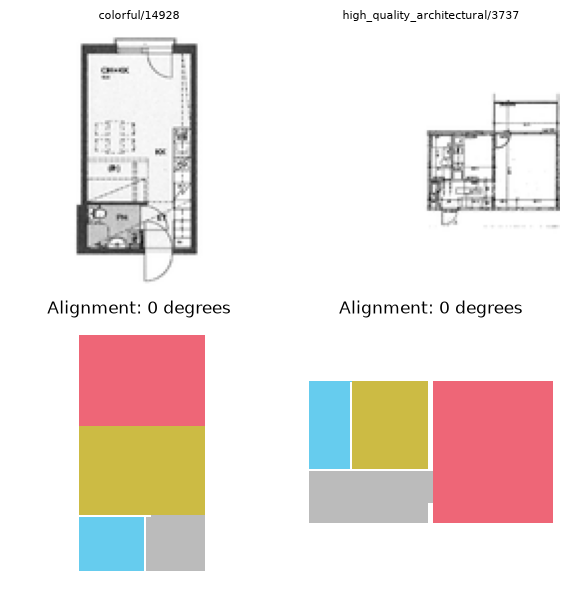

,Review pair
query_id,colorful/14928
candidate_id,high_quality_architectural/3737
relevance,NaN
notes,NaN


In [17]:
PAIR_NUMBER=0
review_path=OUTPUT/'val_review.csv'
if index is not None and review_path.exists():
    sheet=pd.read_csv(review_path)
    if len(sheet):
        pair=sheet.iloc[PAIR_NUMBER]
        show_plans([pair['query_id'],pair['candidate_id']])
        display(pair.to_frame('Review pair'))


## 10. Evaluate relevance and report missing judgements

Report **Precision@5** (fraction labelled 1 or 2), **strong-match fraction@5**, and **pooled nDCG@5** (graded relevance, giving earlier results more weight). The ideal nDCG ranking comes from the judged candidate pool, not the full dataset. If no candidate is relevant, nDCG is undefined; precision remains zero.

A query is scored only when every compared method supplies five distinct results and the whole pooled set is labelled. Blank labels are not zeroes. The complete-query count is essential: do not claim improvement from a tiny reviewed subset. Also report annotation failures and whether the collection was partial.

Use validation reviews to select weights. Freeze them and rebuild the index before generating a separate test pool with `make_review_pool('test')` and evaluating `evaluate_reviews('test')`. Never tune on test judgements.


In [18]:
def evaluate_reviews(split='val'):
    rankings=pd.read_csv(OUTPUT/f'{split}_rankings.csv')
    labels=pd.read_csv(OUTPUT/f'{split}_review.csv')
    keys=['query_id','candidate_id']
    if labels.duplicated(keys).any(): raise ValueError('Duplicate review pairs')
    if rankings.duplicated(['method']+keys).any(): raise ValueError('Duplicate method candidates')
    labels['relevance']=pd.to_numeric(labels['relevance'],errors='raise')
    if not labels['relevance'].dropna().isin([0,1,2]).all():
        raise ValueError('Relevance must be blank, 0, 1 or 2')
    methods=sorted(rankings['method'].unique())
    joined=rankings.merge(labels[keys+['relevance']],on=keys,how='left',validate='many_to_one')
    scores=[]; incomplete=0
    for qid,group in joined.groupby('query_id'):
        top={m:group[group['method'].eq(m)].sort_values('rank').head(5) for m in methods}
        if group['relevance'].isna().any() or any(len(g)!=5 for g in top.values()):
            incomplete+=1; continue
        ideal=group.drop_duplicates('candidate_id')['relevance'].sort_values(ascending=False).to_numpy()[:5]
        discount=np.log2(np.arange(2,7)); idcg=((2**ideal-1)/discount).sum()
        for method,retrieved in top.items():
            relevance=retrieved['relevance'].to_numpy(); dcg=((2**relevance-1)/discount).sum()
            scores.append({'query_id':qid,'method':method,'precision_at_5':(relevance>=1).mean(),
                'strong_at_5':(relevance==2).mean(),'pooled_ndcg_at_5':dcg/idcg if idcg else np.nan})
    print(f'Complete queries: {len(scores)//len(methods)}; incomplete queries: {incomplete}')
    if not scores:
        print('No complete queries. Fill labels; blanks remain unreviewed.')
        return pd.DataFrame()
    details=pd.DataFrame(scores); details.to_csv(OUTPUT/f'{split}_scores.csv',index=False)
    return details.groupby('method').agg(queries=('query_id','size'),
        precision_at_5=('precision_at_5','mean'),strong_at_5=('strong_at_5','mean'),
        pooled_ndcg_at_5=('pooled_ndcg_at_5','mean'),ndcg_queries=('pooled_ndcg_at_5','count'))

if index is not None and review_path.exists(): display(evaluate_reviews())


Complete queries: 0; incomplete queries: 30
No complete queries. Fill labels; blanks remain unreviewed.


""


## 11. Decide what to train from the failure cases

This notebook implements annotation inspection, structural search and relevance review, and section 8 trains a first upload-ready v3 encoder (drawing to rooms). What is left:

1. Fix annotation alignment and rejected plans before modifying the model.
2. If room counts match but positions fail, compare finer grids or room-instance matching. Inspect the effect of the outer silhouette rather than assuming it is gone.
3. Extract room-to-room edges through openings, recording uncertain and exterior connections. Validate them visually before adding a connectivity score.
4. Train a contrastive/triplet layout encoder only once the representation is useful. Use training-only structural positives and reviewed examples, with hard negatives that share counts/footprint but differ internally. Same-plan augmentations alone are insufficient supervision for different-home relevance.
5. Compare the learned encoder with this baseline and v2 using the same reviewed query/gallery protocol.
6. For ordinary uploaded drawings, integrate room/wall extraction and evaluate on **predicted masks**. Ground-truth SVG search is an intermediate experiment and may overestimate app quality.
7. Export the chosen model, preprocessing, category policy and regenerated collection embeddings as one version; then update the server and atlas.

### Experiment log: fill after running

- Dataset location, valid count and annotation failures:
- Overlay inspection, tiny-room/door failures and category observations:
- Query IDs, reviewer and judgement rubric:
- Frozen feature version and weights:
- V2 / structural validation metrics and representative failure cases:
- Decision about connectivity or metric-learning training:
- Availability and quality of the uploaded-image extraction step:

CubiCasa5K attribution and CC BY-NC-SA 4.0 data licensing still apply. Synthetic checks are implementation checks, not measured retrieval results.
